# Porto Taxi Trajectory — Exploratory Data Analysis

This notebook consolidates the EDA and the small data transformations useful for Part 2 of TDT4225 Assignment 2. It checks data structure and quality, examines the report's key distributions, and prepares GPS-point counts, time bands, and sample start/end coordinates.

## 1. Imports and initial inspection

In [1]:
import ast
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = "porto/porto.csv"
CHUNK_SIZE = 100_000

# Read a small sample first, then inspect the dataset structure.
df_sample = pd.read_csv(DATA_PATH, nrows=5)
print("Columns:", df_sample.columns.tolist())
display(df_sample)

# Read metadata columns only for the main data-quality analyses.
metadata_columns = [
    "TRIP_ID", "CALL_TYPE", "ORIGIN_CALL", "ORIGIN_STAND",
    "TAXI_ID", "TIMESTAMP", "DAY_TYPE", "MISSING_DATA"
]
metadata = pd.read_csv(DATA_PATH, usecols=metadata_columns)
print(f"\nDataset rows: {len(metadata):,}")
print(f"Dataset columns: {len(df_sample.columns)}")
print("\nData types:")
print(df_sample.dtypes)
print("\nMissing values by column:")
print(metadata.isna().sum())

Columns: ['TRIP_ID', 'CALL_TYPE', 'ORIGIN_CALL', 'ORIGIN_STAND', 'TAXI_ID', 'TIMESTAMP', 'DAY_TYPE', 'MISSING_DATA', 'POLYLINE']


,TRIP_ID,CALL_TYPE,ORIGIN_CALL,ORIGIN_STAND,TAXI_ID,TIMESTAMP,DAY_TYPE,MISSING_DATA,POLYLINE
0,1372636858620000589,C,NaN,NaN,20000589,1372636858,A,False,"[[-8.618643,41.141412],[-8.618499,41.141376],[..."
1,1372637303620000596,B,NaN,7.0,20000596,1372637303,A,False,"[[-8.639847,41.159826],[-8.640351,41.159871],[..."
2,1372636951620000320,C,NaN,NaN,20000320,1372636951,A,False,"[[-8.612964,41.140359],[-8.613378,41.14035],[-..."
3,1372636854620000520,C,NaN,NaN,20000520,1372636854,A,False,"[[-8.574678,41.151951],[-8.574705,41.151942],[..."
4,1372637091620000337,C,NaN,NaN,20000337,1372637091,A,False,"[[-8.645994,41.18049],[-8.645949,41.180517],[-..."



Dataset rows: 1,710,670
Dataset columns: 9

Data types:
TRIP_ID           int64
CALL_TYPE           str
ORIGIN_CALL     float64
ORIGIN_STAND    float64
TAXI_ID           int64
TIMESTAMP         int64
DAY_TYPE            str
MISSING_DATA       bool
POLYLINE            str
dtype: object

Missing values by column:
TRIP_ID               0
CALL_TYPE             0
ORIGIN_CALL     1345900
ORIGIN_STAND     904091
TAXI_ID               0
TIMESTAMP             0
DAY_TYPE              0
MISSING_DATA          0
dtype: int64


## 2. Duplicate rows and `TRIP_ID` values

In [2]:
# Exact duplicates across all columns (read in chunks to avoid loading POLYLINE twice).
exact_duplicate_count = 0
for chunk in pd.read_csv(DATA_PATH, chunksize=CHUNK_SIZE):
    exact_duplicate_count += chunk.duplicated().sum()

# Count duplicate TRIP_IDs and inspect how duplicated IDs differ.
duplicate_ids = metadata[metadata.duplicated("TRIP_ID", keep=False)].sort_values("TRIP_ID")
print(f"Exact duplicate rows detected within chunks: {exact_duplicate_count:,}")
print(f"Rows belonging to duplicated TRIP_IDs: {metadata.duplicated('TRIP_ID', keep=False).sum():,}")
print(f"Unique duplicated TRIP_IDs: {duplicate_ids['TRIP_ID'].nunique():,}")

if not duplicate_ids.empty:
    full_duplicates = pd.read_csv(DATA_PATH, usecols=[
        "TRIP_ID", "CALL_TYPE", "ORIGIN_CALL", "ORIGIN_STAND",
        "TAXI_ID", "TIMESTAMP", "DAY_TYPE", "MISSING_DATA", "POLYLINE"
    ])
    duplicate_rows = full_duplicates[full_duplicates["TRIP_ID"].isin(duplicate_ids["TRIP_ID"])]
    varying_columns = [
        col for col in duplicate_rows.columns
        if col != "TRIP_ID" and duplicate_rows.groupby("TRIP_ID")[col].nunique(dropna=False).gt(1).any()
    ]
    print("Columns that vary among duplicate IDs:", varying_columns)
    print("\nExample duplicated IDs:")
    print(duplicate_rows.groupby("TRIP_ID").size().sort_values(ascending=False).head(10))
    del full_duplicates, duplicate_rows

Exact duplicate rows detected within chunks: 3
Rows belonging to duplicated TRIP_IDs: 161
Unique duplicated TRIP_IDs: 80
Columns that vary among duplicate IDs: ['CALL_TYPE', 'ORIGIN_CALL', 'ORIGIN_STAND', 'POLYLINE']

Example duplicated IDs:
TRIP_ID
1397172149620000454    3
1372702836620000080    2
1373025987620000601    2
1397199117620000513    2
1397121307620000196    2
1396333938620000397    2
1395682280620000089    2
1395055378620000315    2
1394207135620000588    2
1394118360620000066    2
dtype: int64


## 3. Trip metadata and distributions

Examine the distribution of `CALL_TYPE`, check whether `ORIGIN_CALL` and `ORIGIN_STAND` follow their expected relationships with call type, and summarize taxi, day-type, and missing-data metadata.

Trips by CALL_TYPE:
CALL_TYPE
B    817881
C    528019
A    364770
Name: count, dtype: int64


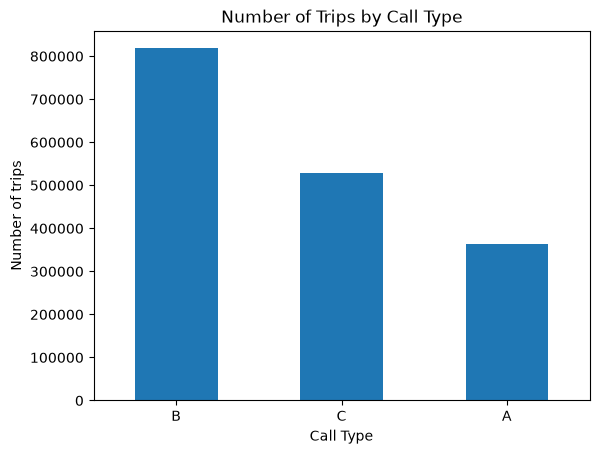


ORIGIN_CALL: unique non-missing client IDs: 57105
Most common ORIGIN_CALL values:
ORIGIN_CALL
2002.0     57571
63882.0     6406
2001.0      2499
13168.0     1314
6728.0      1115
5591.0      1051
14123.0      990
6654.0       909
2024.0       800
14045.0      769
Name: count, dtype: int64
Rows with ORIGIN_CALL set when CALL_TYPE is not A: 0
Rows with ORIGIN_CALL missing when CALL_TYPE is A: 0

ORIGIN_STAND: unique non-missing stand IDs: 63
Most common ORIGIN_STAND values:
ORIGIN_STAND
15.0    80241
57.0    50882
9.0     34818
33.0    34128
23.0    33344
18.0    32937
53.0    31712
13.0    25685
12.0    25434
36.0    24754
Name: count, dtype: int64
CALL_TYPE B rows without ORIGIN_STAND: 11302
ORIGIN_STAND set when CALL_TYPE is not B: 0

Trips per taxi summary:
count      448.000000
mean      3818.459821
std       1644.021173
min          1.000000
25%       2694.000000
50%       3732.000000
75%       5023.250000
max      10746.000000
Name: count, dtype: float64

Taxis with the most trip

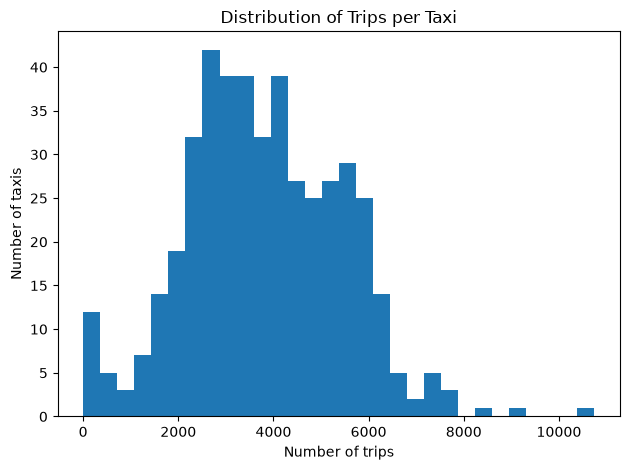


DAY_TYPE distribution:
DAY_TYPE
A    1710670
Name: count, dtype: int64

MISSING_DATA distribution:
MISSING_DATA
False    1710660
True          10
Name: count, dtype: int64


In [9]:
print("Trips by CALL_TYPE:")
call_type_counts = metadata["CALL_TYPE"].value_counts(dropna=False)
print(call_type_counts)


call_type_counts.plot(kind="bar")
plt.title("Number of Trips by Call Type")
plt.xlabel("Call Type")
plt.ylabel("Number of trips")
plt.xticks(rotation=0)
plt.show()

print("\nORIGIN_CALL: unique non-missing client IDs:", metadata["ORIGIN_CALL"].nunique())
print("Most common ORIGIN_CALL values:")
print(metadata.loc[metadata["CALL_TYPE"].eq("A"), "ORIGIN_CALL"].value_counts().head(10))
print("Rows with ORIGIN_CALL set when CALL_TYPE is not A:",
      (metadata["ORIGIN_CALL"].notna() & metadata["CALL_TYPE"].ne("A")).sum())
print("Rows with ORIGIN_CALL missing when CALL_TYPE is A:",
      (metadata["ORIGIN_CALL"].isna() & metadata["CALL_TYPE"].eq("A")).sum())

print("\nORIGIN_STAND: unique non-missing stand IDs:", metadata["ORIGIN_STAND"].nunique())
print("Most common ORIGIN_STAND values:")
print(metadata.loc[metadata["CALL_TYPE"].eq("B"), "ORIGIN_STAND"].value_counts().head(10))
print("CALL_TYPE B rows without ORIGIN_STAND:",
      (metadata["CALL_TYPE"].eq("B") & metadata["ORIGIN_STAND"].isna()).sum())
print("ORIGIN_STAND set when CALL_TYPE is not B:",
      (metadata["ORIGIN_STAND"].notna() & metadata["CALL_TYPE"].ne("B")).sum())

trips_per_taxi = metadata["TAXI_ID"].value_counts()
print("\nTrips per taxi summary:")
print(trips_per_taxi.describe())
print("\nTaxis with the most trips:")
print(trips_per_taxi.head(10))
print("\nTaxis with the fewest trips:")
print(trips_per_taxi.tail(10))
trips_per_taxi.plot(kind="hist", bins=30)
plt.title("Distribution of Trips per Taxi")
plt.xlabel("Number of trips")
plt.ylabel("Number of taxis")
plt.tight_layout()
plt.show()

print("\nDAY_TYPE distribution:")
print(metadata["DAY_TYPE"].value_counts(dropna=False))
print("\nMISSING_DATA distribution:")
print(metadata["MISSING_DATA"].value_counts(dropna=False))

## 4. Timestamp quality and monthly distribution

Missing timestamps: 0
Invalid timestamps: 0
Valid timestamps: 1710670
Earliest timestamp: 2013-07-01 00:00:53
Latest timestamp: 2014-06-30 23:59:56

Monthly trip counts:
  Month  Number of Trips
2013-07           145640
2013-08           125861
2013-09           147514
2013-10           153394
2013-11           140024
2013-12           146258
2014-01           130875
2014-02           129872
2014-03           138969
2014-04           137061
2014-05           162107
2014-06           153095


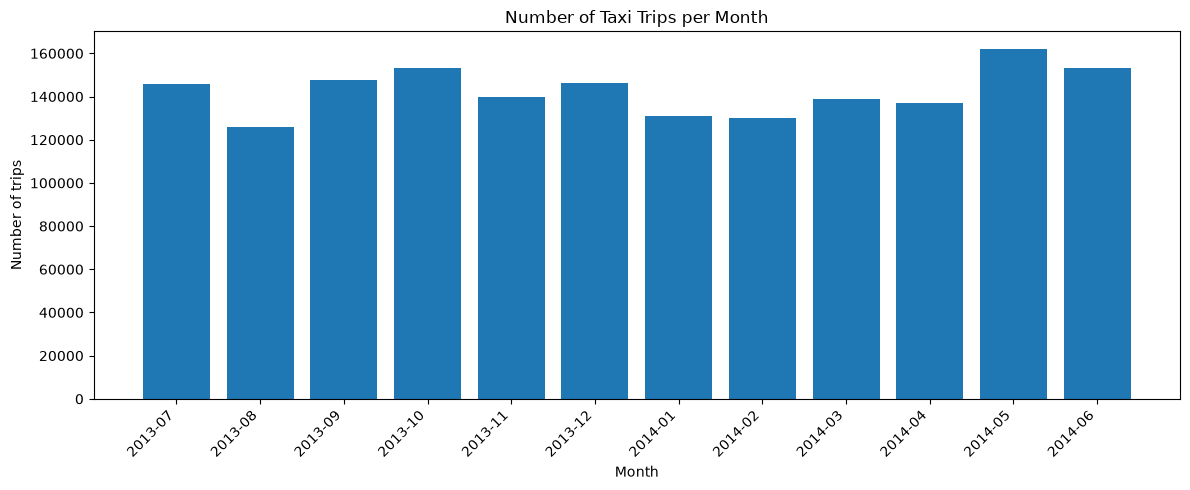


Trips by start-time band:
TIMESTAMP
00-06    313907
06-12    491539
12-18    527958
18-24    377266
Name: count, dtype: int64

Share of trips by start-time band (%):
TIMESTAMP
00-06    18.35
06-12    28.73
12-18    30.86
18-24    22.05
Name: count, dtype: float64

Share of trips by time band within each call type (%):
TIMESTAMP  00-06  06-12  12-18  18-24
CALL_TYPE                            
A          11.93  33.35  32.17  22.55
B          12.24  30.12  34.46  23.18
C          32.26  23.39  24.39  19.96


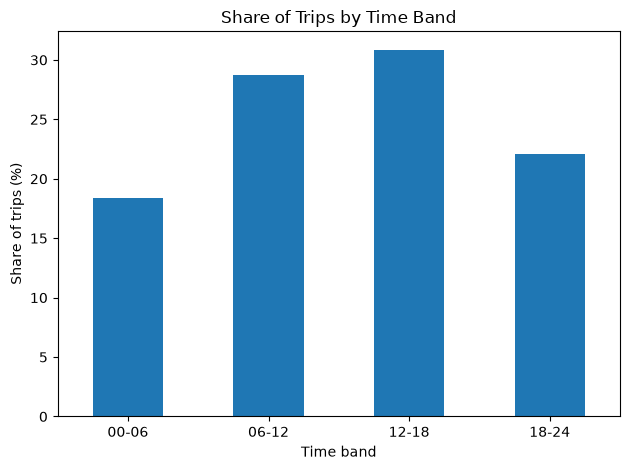

In [4]:
timestamps = pd.to_numeric(metadata["TIMESTAMP"], errors="coerce")
datetimes = pd.to_datetime(timestamps, unit="s", errors="coerce")
print("Missing timestamps:", metadata["TIMESTAMP"].isna().sum())
print("Invalid timestamps:", (timestamps.notna() & datetimes.isna()).sum())
print("Valid timestamps:", datetimes.notna().sum())
print("Earliest timestamp:", datetimes.min())
print("Latest timestamp:", datetimes.max())

monthly_counts = datetimes.dropna().dt.to_period("M").value_counts().sort_index()
monthly_df = monthly_counts.rename_axis("Month").rename("Number of Trips").reset_index()
monthly_df["Month"] = monthly_df["Month"].astype(str)
print("\nMonthly trip counts:")
print(monthly_df.to_string(index=False))
plt.figure(figsize=(12, 5))
plt.bar(monthly_df["Month"], monthly_df["Number of Trips"])
plt.title("Number of Taxi Trips per Month")
plt.xlabel("Month")
plt.ylabel("Number of trips")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Time bands used in Part 2, Question 4b.
time_bands = ["00-06", "06-12", "12-18", "18-24"]
hours = datetimes.dt.hour
band = pd.cut(hours, bins=[-1, 5, 11, 17, 23], labels=time_bands)
time_band_counts = band.value_counts().reindex(time_bands, fill_value=0)
call_type_time_bands = pd.crosstab(metadata["CALL_TYPE"], band).reindex(
    index=["A", "B", "C"], columns=time_bands, fill_value=0
)
print("\nTrips by start-time band:")
print(time_band_counts)
print("\nShare of trips by start-time band (%):")
print((time_band_counts / time_band_counts.sum() * 100).round(2))
print("\nShare of trips by time band within each call type (%):")
print((call_type_time_bands.div(call_type_time_bands.sum(axis=1), axis=0) * 100).round(2))
(time_band_counts / time_band_counts.sum() * 100).plot(kind="bar")
plt.title("Share of Trips by Time Band")
plt.xlabel("Time band")
plt.ylabel("Share of trips (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Trajectory length and invalid trips

Each point in `POLYLINE` is sampled at 15-second intervals. A trip is invalid for Part 2, Question 7 if it has fewer than three GPS points. Empty trajectories are included in that invalid-trip count.

GPS points per trip:
count    1.710670e+06
mean     4.875831e+01
std      4.565372e+01
min      0.000000e+00
25%      2.800000e+01
50%      4.100000e+01
75%      5.900000e+01
max      3.881000e+03
Name: POLYLINE, dtype: float64
Empty trajectories: 5901
Trips with fewer than 3 GPS points: 43904
Non-empty trips with fewer than 3 GPS points: 38003
Total GPS points: 83,409,386


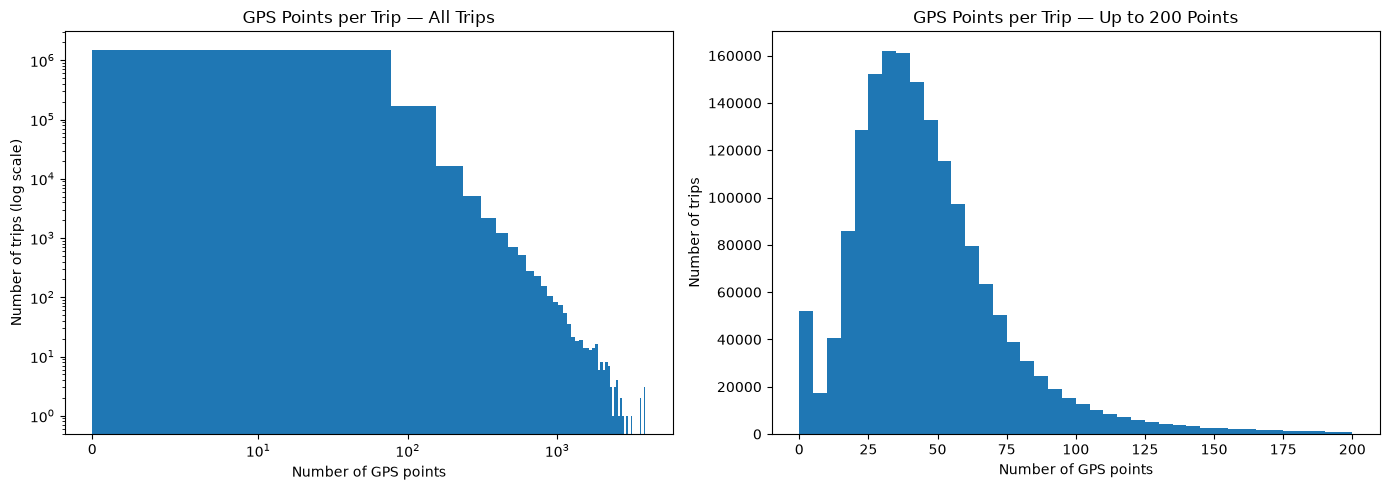

In [5]:
# Count points by counting separators in each trajectory string; [] means zero points.
gps_point_counts = []
for chunk in pd.read_csv(DATA_PATH, usecols=["POLYLINE"], chunksize=CHUNK_SIZE):
    points = chunk["POLYLINE"].str.count(r"\]\s*,\s*\[") + 1
    points = points.mask(chunk["POLYLINE"].eq("[]"), 0).fillna(0).astype("int64")
    gps_point_counts.append(points)
num_gps_points = pd.concat(gps_point_counts, ignore_index=True)

print("GPS points per trip:")
print(num_gps_points.describe())
print("Empty trajectories:", (num_gps_points == 0).sum())
print("Trips with fewer than 3 GPS points:", (num_gps_points < 3).sum())
print("Non-empty trips with fewer than 3 GPS points:", ((num_gps_points > 0) & (num_gps_points < 3)).sum())
print("Total GPS points:", f"{num_gps_points.sum():,}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(num_gps_points, bins=50, log=True)
axes[0].set_xscale("symlog", linthresh=10)
axes[0].set_title("GPS Points per Trip — All Trips")
axes[0].set_xlabel("Number of GPS points")
axes[0].set_ylabel("Number of trips (log scale)")
axes[1].hist(num_gps_points[num_gps_points <= 200], bins=40)
axes[1].set_title("GPS Points per Trip — Up to 200 Points")
axes[1].set_xlabel("Number of GPS points")
axes[1].set_ylabel("Number of trips")
plt.tight_layout()
plt.show()

## 6. Estimated trip duration and outliers

Estimated duration in minutes:
count    1.704769e+06
mean     1.198177e+01
std      1.141057e+01
min      0.000000e+00
25%      6.750000e+00
50%      1.000000e+01
75%      1.450000e+01
max      9.700000e+02
Name: POLYLINE, dtype: float64

Q1: 6.75 minutes
Q3: 14.50 minutes
IQR: 7.75 minutes
Upper outlier threshold: 26.12 minutes
Trips above threshold: 78,777 (4.62%)
Longest estimated duration: 970.00 minutes

Duration statistics with all non-empty trips:
count    1.704769e+06
mean     1.198177e+01
std      1.141057e+01
min      0.000000e+00
25%      6.750000e+00
50%      1.000000e+01
75%      1.450000e+01
max      9.700000e+02
Name: POLYLINE, dtype: float64

Duration statistics excluding IQR outliers:
count    1.625992e+06
mean     1.044291e+01
std      5.332534e+00
min      0.000000e+00
25%      6.500000e+00
50%      9.750000e+00
75%      1.375000e+01
max      2.600000e+01
Name: POLYLINE, dtype: float64


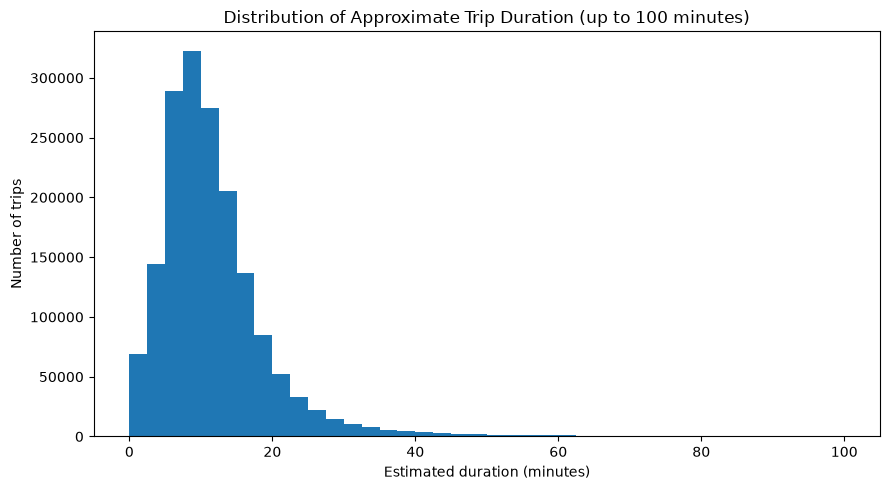


Longest trajectories:
            TRIP_ID            DATETIME  MISSING_DATA  GPS_POINTS  DURATION_MINUTES
1393061275620000681 2014-02-22 09:27:55         False        3881            970.00
1400312076620000562 2014-05-17 07:34:36         False        3872            967.75
1383293324620000520 2013-11-01 08:08:44         False        3836            958.75
1376892235620000086 2013-08-19 06:03:55         False        3590            897.25
1375289927620000902 2013-07-31 16:58:47         False        3571            892.50
1379954402620000904 2013-09-23 16:40:02         False        3120            779.75
1375981643620000520 2013-08-08 17:07:23         False        2935            733.50
1395081407620000904 2014-03-17 18:36:47         False        2739            684.50
1391442237620000902 2014-02-03 15:43:57         False        2679            669.50
1388220860620000144 2013-12-28 08:54:20         False        2653            663.00


In [6]:
# Empty trajectories cannot provide an estimated duration.
duration_minutes = (num_gps_points[num_gps_points > 0] - 1) * 15 / 60
print("Estimated duration in minutes:")
print(duration_minutes.describe())

q1, q3 = duration_minutes.quantile([0.25, 0.75])
iqr = q3 - q1
outlier_threshold = q3 + 1.5 * iqr
outliers = duration_minutes[duration_minutes > outlier_threshold]
without_outliers = duration_minutes[duration_minutes <= outlier_threshold]
print(f"\nQ1: {q1:.2f} minutes")
print(f"Q3: {q3:.2f} minutes")
print(f"IQR: {iqr:.2f} minutes")
print(f"Upper outlier threshold: {outlier_threshold:.2f} minutes")
print(f"Trips above threshold: {len(outliers):,} ({len(outliers) / len(duration_minutes) * 100:.2f}%)")
print(f"Longest estimated duration: {duration_minutes.max():.2f} minutes")
print("\nDuration statistics with all non-empty trips:")
print(duration_minutes.describe())
print("\nDuration statistics excluding IQR outliers:")
print(without_outliers.describe())

plt.figure(figsize=(9, 5))
plt.hist(duration_minutes[duration_minutes <= 100], bins=40)
plt.title("Distribution of Approximate Trip Duration (up to 100 minutes)")
plt.xlabel("Estimated duration (minutes)")
plt.ylabel("Number of trips")
plt.tight_layout()
plt.show()

# Show the longest trips for contextual inspection.
longest_indices = num_gps_points.nlargest(10).index
longest_trips = metadata.loc[longest_indices, ["TRIP_ID", "TIMESTAMP", "MISSING_DATA"]].copy()
longest_trips["GPS_POINTS"] = num_gps_points.loc[longest_indices].values
longest_trips["DURATION_MINUTES"] = (longest_trips["GPS_POINTS"] - 1) * 15 / 60
longest_trips["DATETIME"] = pd.to_datetime(longest_trips["TIMESTAMP"], unit="s", errors="coerce")
print("\nLongest trajectories:")
print(longest_trips[["TRIP_ID", "DATETIME", "MISSING_DATA", "GPS_POINTS", "DURATION_MINUTES"]].to_string(index=False))

## 7. Inspect trips flagged with `MISSING_DATA = True`

In [10]:
# Inspect trips flagged with missing GPS data.
missing_mask = metadata["MISSING_DATA"].astype(str).str.lower().eq("true")

missing_trips = metadata.loc[
    missing_mask, ["TRIP_ID", "MISSING_DATA"]
].copy()

missing_trips["POINT_COUNT"] = num_gps_points.loc[missing_trips.index]
missing_trips["EST_DURATION_MIN"] = (
    (missing_trips["POINT_COUNT"] - 1).clip(lower=0) * 0.25
)

print(missing_trips[
    ["TRIP_ID", "MISSING_DATA", "POINT_COUNT", "EST_DURATION_MIN"]
].sort_values("POINT_COUNT").to_string(index=False))

print(
    "\nFlagged trips with fewer than 3 points:",
    (missing_trips["POINT_COUNT"] < 3).sum()
)

            TRIP_ID  MISSING_DATA  POINT_COUNT  EST_DURATION_MIN
1375863510620000454          True            1              0.00
1396631707620000163          True            1              0.00
1378544246620000057          True           11              2.50
1390005983620000640          True           14              3.25
1388351478620000678          True           27              6.50
1374554455620000625          True           43             10.50
1387137779620000640          True           51             12.50
1399405185620000508          True           53             13.00
1386346894620000904          True          285             71.00
1381233613620000387          True          483            120.50

Flagged trips with fewer than 3 points: 2


## 8. Demonstrate start/end coordinate extraction

In [8]:
# A small sample demonstrates the transformation needed for distance-based Part 2 queries.
polyline_sample = pd.read_csv(DATA_PATH, usecols=["POLYLINE"], nrows=5)
polyline_sample["POLYLINE"] = polyline_sample["POLYLINE"].apply(
    lambda value: ast.literal_eval(value) if isinstance(value, str) else []
)
polyline_sample["START_POINT"] = polyline_sample["POLYLINE"].apply(lambda points: points[0] if points else None)
polyline_sample["END_POINT"] = polyline_sample["POLYLINE"].apply(lambda points: points[-1] if points else None)
display(polyline_sample[["START_POINT", "END_POINT"]])

,START_POINT,END_POINT
0,"[-8.618643, 41.141412]","[-8.630838, 41.154489]"
1,"[-8.639847, 41.159826]","[-8.66574, 41.170671]"
2,"[-8.612964, 41.140359]","[-8.61597, 41.14053]"
3,"[-8.574678, 41.151951]","[-8.607996, 41.142915]"
4,"[-8.645994, 41.18049]","[-8.687268, 41.178087]"


## Summary

The EDA examined the dataset's structure, distributions, and data quality. The dataset contains 1,710,670 trips from 448 taxis, with 83,409,386 GPS points in total. Key findings include 43,904 trips with fewer than three GPS points, 10 trips flagged with missing data, and duplicated trip IDs requiring further consideration. The analysis also explored trip durations, call types, and temporal patterns to inform data preparation and the subsequent database queries.